In [13]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'/projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct'

In [14]:
import sys, os

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
import project

add_path(os.environ['PROJECT'] + '/' + 'param_search')
import param_search as ps

ps.set_backend('sge')
ps.set_verbose(False)

# Gather examples

In [15]:
from pathlib import Path
data_root = Path(os.environ['PRIVATE']) / 'data' / 'BMC-4DCT'
data_root.exists()

True

In [16]:
manifest_path = data_root / 'metadata' / 'phase_manifest.csv'
manifest = project.fileio.load_csv(manifest_path)
manifest.head()

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/metadata/phase_manifest.csv


,case_id,subject_num,study_num,scan_role,resp_phase,image_path,series_description,case_phases,case_valid
0,4DCT_10_1,10,1,4DCT,0.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,0 0% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
1,4DCT_10_1,10,1,4DCT,10.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,10 10% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
2,4DCT_10_1,10,1,4DCT,20.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,20 20% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
3,4DCT_10_1,10,1,4DCT,30.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,30 30% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
4,4DCT_10_1,10,1,4DCT,40.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,40 40% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True


In [17]:
# valid 4DCT cases have a complete ten-phase respiratory series
case_data = manifest[manifest.case_valid].sort_values(by=['subject_num', 'study_num'])
case_list = case_data.case_id.unique().tolist()
len(case_list)

47

In [18]:
# all subjects have a single scan role
case_data.groupby(['subject_num'])['scan_role'].nunique().agg(['mean', 'min', 'max'])

mean    1.0
min     1.0
max     1.0
Name: scan_role, dtype: float64

In [19]:
# most subjects have one study; some have two
case_data.groupby(['subject_num'])['study_num'].nunique().agg(['mean', 'min', 'max'])

mean    1.119048
min     1.000000
max     2.000000
Name: study_num, dtype: float64

In [20]:
config = project.fileio.load_config('2026-11-01_config.yaml')

config['dataset']['variant'] = '2026-11-01'
config['dataset']['subjects'] = case_list
config['dataset']['state_pairs'] = [(50, 0)]
config['dataset']['pipeline_tags']['image_registration']  = 'gil'
config['dataset']['pipeline_tags']['material_properties'] = 'const'
config['dataset']['pipeline_tags']['field_interpolation'] = 'int'

config['training']['split']['method'] = 'metadata'
config['training']['split']['key'] = 'subject_num'
config['training']['split']['test_ratio'] = 0.2
config['training']['split']['val_ratio'] = 0.2
config['training']['split']['seed'] = 11

examples = project.get_examples(config['dataset'])

Loading 2026-11-01_config.yaml
Gathering examples...
47 total


In [21]:
import project.training.splits
project.utils.set_verbose(False)

def has_multi_study(examples):
    from collections import defaultdict
    cases_by_subject = defaultdict(set)
    for ex in examples:
        cases_by_subject[ex.metadata['subject_num']].add(ex.subject)
    return any(len(cases) > 1 for cases in cases_by_subject.values())

for seed in range(9999):
    config['training']['split']['seed'] = seed
    train_exs, test_exs, val_exs = project.training.splits.split_data(
        examples, **config['training']['split']
    )
    eval_on_annotated = all(
        ex.metadata['scan_role'] == 'unknown' for ex in test_exs + val_exs
    )
    if eval_on_annotated and has_multi_study(val_exs) and has_multi_study(test_exs):
        break

project.utils.set_verbose(True)
print(seed)

11


In [22]:
config['training']['split']['seed'] = 11

train_exs, test_exs, val_exs = project.training.splits.split_data(
    examples, **config['training']['split']
)

case_split = {
    'train': [ex.subject for ex in train_exs],
    'test': [ex.subject for ex in test_exs],
    'val': [ex.subject for ex in val_exs],
}

Splitting data examples
All subject_num levels: 42 [1, 2, 4, 6, 7, 8, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 42, 43, 44, 45, 47, 49, 50, 51, 52, 53]
Test ratio: 0.20
Val ratio:  0.20
Split seed: 11
Train subject_num levels: 26 [50, 2, 20, 10, 8, 45, 7, 49, 16, 34, 37, 1, 12, 32, 53, 14, 26, 4, 36, 13, 42, 6, 44, 38, 52, 23]
Test subject_num levels:  8 [17, 33, 43, 30, 31, 29, 47, 28]
Val subject_num levels:   8 [40, 18, 27, 39, 15, 51, 22, 19]
Train examples: 29 ['4DCT_10_1', '4DCT_1_1', '4DCT_2_1', '4DCT_2_2', '4DCT_4_1', '4DCT_6_1', '4DCT_7_3', '4DCT_8_1', '4DCT_8_2', 'unknown_12_1', 'unknown_13_1', 'unknown_14_1', 'unknown_16_1', 'unknown_20_1', 'unknown_23_1', 'unknown_26_1', 'unknown_32_1', 'unknown_34_1', 'unknown_36_1', 'unknown_37_1', 'unknown_38_1', 'unknown_42_1', 'unknown_42_4', 'unknown_44_1', 'unknown_45_1', 'unknown_49_1', 'unknown_50_1', 'unknown_52_1', 'unknown_53_1']
Test examples:  9 ['unknown_17_1', 'un

# Setup experiment

In [23]:
base_dir = '2026-11-07_optimize'

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=16G
#$ -l h_rt=6:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHOPATH

python $LP_ROOT/scripts/optimize.py {config} \\
    --set dataset.subjects=[{subject}] \\
    --set dataset.variant={variant} \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set optimization.pde_solver.material_type={material_type} \\
    --set optimization.pde_solver.tv_reg_weight={tv_reg_weight} \\
    --set optimization.pde_solver.verbose=true \\
    --set optimization.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subject=case_list[:10],
    reg_tag=['gil'],
    mat_tag=['const', 'image'],
    material_type=['LE', 'NH'],
    tv_reg_weight=[1e-4],
    random_seed=[0]
)

len(grid)

40

In [24]:
base_dir = '2026-11-08_optimize'

# changelist:
# - one job per case ID x phase pair
# - clamp E params to v_min = 1 Pa
# - relax L-BFGS tolerance values

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=16G
#$ -l h_rt=6:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH

python $LP_ROOT/scripts/optimize.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects=[{subject}] \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set optimization.pde_solver.material_type={material_type} \\
    --set optimization.pde_solver.tv_reg_weight={tv_reg_weight} \\
    --set optimization.pde_solver.newton_atol=5e-5 \\
    --set optimization.pde_solver.verbose=true \\
    --set optimization.optimization_kws.tolerance_grad=1e-10 \\
    --set optimization.optimization_kws.tolerance_change=1e-12 \\
    --set optimization.seed=0

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subject=case_list,
    curr_phase=[40,30,20,10,0,90,80,70,60],
    reg_tag='gil',
    mat_tag=['const', 'image'],
    material_type=['LE', 'NH'],
    tv_reg_weight=1e-4
)

len(grid)

1692

In [25]:
base_dir = '2026-11-11_optimize'

# changelist:
# - only evaluate val + test cases
# - reduce num_trials from 10 to 3
# - limit CG/GMRES maxiter = 10000
# - unmasked field interpolation

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=16G
#$ -l h_rt=6:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH

python $LP_ROOT/scripts/optimize.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects=[{subject}] \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set optimization.pde_solver.material_type={material_type} \\
    --set optimization.pde_solver.tv_reg_weight={tv_reg_weight} \\
    --set optimization.pde_solver.cg_maxiter=10000 \\
    --set optimization.pde_solver.newton_atol=5e-5 \\
    --set optimization.pde_solver.verbose=true \\
    --set optimization.optimization_kws.num_trials={num_trials} \\
    --set optimization.optimization_kws.tolerance_grad=1e-10 \\
    --set optimization.optimization_kws.tolerance_change=1e-12 \\
    --set optimization.seed=0

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subject=case_split['val'] + case_split['test'],
    curr_phase=[40,30,20,10,0,90,80,70,60],
    reg_tag='gil',
    mat_tag=['const'],
    material_type=['LE', 'NH'],
    tv_reg_weight=1e-4,
    num_trials=3
)

len(grid) # 324

324

In [41]:
base_dir = '2026-11-15_optimize'

# changelist:
# - set eps_err=1e-12 (prev: 1e-6)

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=16G
#$ -l h_rt=6:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH

python $LP_ROOT/scripts/optimize.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects=[{subject}] \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set optimization.parameters.E.v_max={E_max} \\
    --set optimization.parameters.E.beta={E_beta} \\
    --set optimization.pde_solver.material_type={material_type} \\
    --set optimization.pde_solver.tv_reg_weight=1e-4 \\
    --set training.pde_solver.eps_err=1e-12 \\
    --set optimization.pde_solver.cg_maxiter=10000 \\
    --set optimization.pde_solver.newton_atol=5e-5 \\
    --set optimization.pde_solver.verbose=true \\
    --set optimization.optimization_kws.num_trials={num_trials} \\
    --set optimization.optimization_kws.tolerance_grad=1e-10 \\
    --set optimization.optimization_kws.tolerance_change=1e-12 \\
    --set optimization.seed=0

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subject=case_split['val'] + case_split['test'],
    curr_phase=[0,10,20,30,40,60,70,80,90],
    reg_tag='gil',
    mat_tag='const',
    E_max=[1e5],
    E_beta=[None],
    material_type=['LE', 'NH'],
    num_trials=3
)

len(grid) # 324

324

In [42]:
jobs = ps.setup(base_dir, template, name_format, grid, overwrite=True)
jobs

,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,params.config,params.variant,params.subject,params.curr_phase,params.reg_tag,params.mat_tag,params.E_max,params.E_beta,params.material_type,params.num_trials
0,job_48a828b75824f177,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_15_1,0,gil,const,100000.0,None,LE,3
1,job_6735d062ca9b7922,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_15_1,0,gil,const,100000.0,None,NH,3
2,job_8a67d41d3dd0e4a0,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_15_1,10,gil,const,100000.0,None,LE,3
3,job_2663a197326d9c70,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_15_1,10,gil,const,100000.0,None,NH,3
4,job_5a21a2e99f7ce373,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_15_1,20,gil,const,100000.0,None,LE,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319,job_036e4d735d9dddec,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_47_1,70,gil,const,100000.0,None,NH,3
320,job_7424b83d9839d636,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_47_1,80,gil,const,100000.0,None,LE,3
321,job_5126f400bc723777,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_47_1,80,gil,const,100000.0,None,NH,3
322,job_6d4e762e741dcc7c,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_47_1,90,gil,const,100000.0,None,LE,3


In [43]:
#jobs.loc[jobs.job_state.isin({'FAILED', 'NEW'}), 'job_id'] = pd.NA
jobs = ps.submit(jobs)

# Monitor submitted jobs

In [29]:
jobs = ps.load('2026-11-15_optimize')

In [10]:
jobs = ps.recover(jobs)
jobs = ps.status(jobs)
jobs = ps.history(jobs)
jobs = ps.collect(jobs)

jobs.groupby('job_state').size()

job_state
COMPLETED    323
FAILED         1
dtype: int64

In [11]:
import pandas as pd

def classify_output(stdout: str):
    if pd.isnull(stdout):
        return 'No stdout file'
    elif not str(stdout).strip():
        return 'No output message'
    elif 'Done' in stdout:
        return 'Done'
    return 'Not done'

def classify_error(stderr: str):
    if pd.isnull(stderr):
        return 'No stderr file'    
    elif not str(stderr).strip():
        return 'No error message'
    elif 'Segmentation fault' in stderr:
        return 'Segmentation fault'
    elif 'CUDA out of memory' in stderr:
        return 'CUDA out of memory'
    elif 'No CUDA GPUs are available' in stderr:
        return 'CUDA not available'
    elif 'Warp UserWarning: grad() call for function' in stderr:
        return 'Warp grad call warning'
    elif 'WARNING: Newton solver failed to converge' in stderr:
        return 'Newton solver warning'
    elif 'Non-positive shear modulus' in stderr:
        return 'Non-positive elasticity'
    return 'Uncategorized'

def parse_runtime(runtime: str):
    import datetime as dt
    if pd.isna(runtime):
        return None
    parts = runtime.split('-', 1)
    days = int(parts[0]) if len(parts) > 1 else 0
    t = dt.datetime.strptime(parts[-1], "%H:%M:%S")
    return dt.timedelta(days=days, hours=t.hour, minutes=t.minute, seconds=t.second).total_seconds()

jobs['error_type'] = jobs.stderr.map(classify_error)
jobs['output_type'] = jobs.stdout.map(classify_output)
jobs['rt_seconds'] = jobs.runtime.map(parse_runtime)
jobs['timed_out'] = jobs['rt_seconds'] > 5 * 60 * 60

jobs.groupby(['params.material_type', 'job_state', 'timed_out', 'output_type', 'error_type'])[['job_name']].count()

job_name
params.material_type job_state timed_out output_type error_type                     
LE                   COMPLETED False     Done        No error message            162
NH                   COMPLETED False     Done        Newton solver warning         7
                                                     No error message            154
                     FAILED    True      Not done    Newton solver warning         1

In [12]:
query_jobs = jobs.query('output_type == "Not done" & timed_out == True')
query_jobs

,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,state_source,finalized,finalized_at,output_exists,output_fsize,output_mtime,error_type,output_type,rt_seconds,timed_out
83,job_5095827e79a9b624,FAILED,1,8581835,scc-x06,06:00:01,[eval 15] alpha = 0.0001 delta = 3.6380e-12...,WARNING: Newton solver failed to converge (ite...,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,history,True,2026-11-12T09:05:03,False,<NA>,<NA>,Newton solver warning,Not done,21601.0,True


In [40]:
job = query_jobs.iloc[0]
print(job)
print(job.stdout)
print(job.stderr)

job_name                                             job_7706ac8429499663
job_state                                                          FAILED
n_submits                                                               2
job_id                                                            8544743
node_id                                                           scc-308
runtime                                                          06:00:01
stdout                  [iter 5] det_F = -0.6315  PDE ares = 1.5372e-0...
stderr                                                                   
base_dir                /projectnb/batmanlab/mragoza/lung-project/note...
work_dir                /projectnb/batmanlab/mragoza/lung-project/note...
script_path             /projectnb/batmanlab/mragoza/lung-project/note...
output_path             /projectnb/batmanlab/mragoza/lung-project/note...
log_dir                 /projectnb/batmanlab/mragoza/lung-project/note...
stdout_path             /projectnb/bat

# Analyze outputs

In [36]:
from pathlib import Path
job = jobs.iloc[0]
raster_path = Path(job.work_dir) / 'outputs' / 'optimize' / 'default' / job['params.subject'] / 'rasters' / 'E_pred.nii.gz'
E_pred = project.fileio.load_nibabel(raster_path).get_fdata()

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_48a828b75824f177/outputs/optimize/default/unknown_15_1/rasters/E_pred.nii.gz


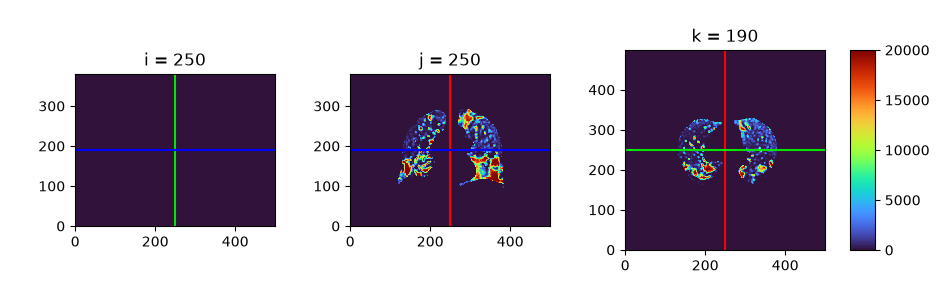

In [40]:
import project.visual.matplotlib as mpl_viz

mpl_viz.SliceViewer(E_pred, cmap='turbo', clim=(0,2e4))

In [41]:
df = ps.outputs(
    jobs,
    meta_cols=['job_name', 'job_id'],
    output_name='outputs/optimize/default/eval_metrics.csv',
    read_csv_kws={'index_col': 0},
    skip_errors=True
)
df

  2%|▏         | 37/1692 [00:00<00:13, 119.63it/s]Job job_7706ac8429499663: file not found
Job job_d8f2c242370dd27a: file not found
Job job_cda06286edb5de77: file not found
Job job_83cdc9b048515d2b: file not found
Job job_2b8e914470af8cf9: file not found
Job job_2ae024b21e9e66bd: file not found
  3%|▎         | 55/1692 [00:00<00:11, 142.02it/s]Job job_6e1146c4a1b83079: file not found
Job job_e98e7aeb508df8c1: file not found
Job job_5cb6d24515e4f9bb: file not found
Job job_a24be27d95dbf04d: file not found
Job job_4be727f8169537c5: file not found
Job job_2637222c6f7fc571: file not found
Job job_f4dc0c11eff3f357: file not found
 11%|█         | 186/1692 [00:01<00:11, 125.61it/s]Job job_60b4edd394ab2a56: file not found
Job job_c887d503f9cd2107: file not found
Job job_5843db1a77cca71e: file not found
Job job_21514c54f4408c04: file not found
Job job_06a15f852fb5f925: file not found
 12%|█▏        | 203/1692 [00:01<00:10, 136.24it/s]Job job_ae3521bdc1efaf97: file not found
Job job_39a9ca988ab

,group,label,num_voxels,E_vox.mean,E_vox.std,E_vox.rms,num_cells,E_cell.mean,E_cell.std,E_cell.rms,...,job_id,params.config,params.variant,params.subject,params.curr_phase,params.reg_tag,params.mat_tag,params.material_type,params.tv_reg_weight,params.random_seed
0,NaN,NaN,2250322,9862.096392,16277.148648,19031.723867,188220,9892.391572,14903.220079,17887.576129,...,8529437,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,4DCT_1_1,40,gil,const,LE,0.0001,0
1,NaN,NaN,2250322,9852.997349,16298.164959,19044.992459,188220,9884.364912,14941.283935,17914.871904,...,8529438,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,4DCT_1_1,40,gil,const,NH,0.0001,0
2,NaN,NaN,2250322,9804.937626,16145.931297,18889.888811,188220,9835.351980,14690.680138,17679.090234,...,8529439,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,4DCT_1_1,40,gil,image,LE,0.0001,0
3,NaN,NaN,2250322,9802.689800,15974.422627,18742.329247,188220,9832.351922,14528.385031,17542.779595,...,8529440,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,4DCT_1_1,40,gil,image,NH,0.0001,0
4,NaN,NaN,2250322,6264.467670,13693.809941,15058.684733,188220,6279.416822,12727.315059,14192.097246,...,8529441,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,4DCT_1_1,30,gil,const,LE,0.0001,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
312,NaN,NaN,2993100,9531.007229,20646.291937,22740.041107,249143,9554.683779,19517.774515,21730.980285,...,8529791,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_12_1,70,gil,image,LE,0.0001,0
313,NaN,NaN,2993100,17299.972302,24967.791881,30375.642759,249143,17337.594796,23305.813107,29047.428766,...,8529793,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_12_1,60,gil,const,LE,0.0001,0
314,NaN,NaN,2993100,17414.191530,25070.254391,30524.936067,249143,17452.358421,23415.119482,29203.640780,...,8529794,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_12_1,60,gil,const,NH,0.0001,0
315,NaN,NaN,2993100,13305.639098,22705.796854,26317.166310,249143,13336.386012,21513.915270,25312.205397,...,8529795,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,unknown_12_1,60,gil,image,LE,0.0001,0


In [42]:
df.columns

Index(['group', 'label', 'num_voxels', 'E_vox.mean', 'E_vox.std', 'E_vox.rms',
       'num_cells', 'E_cell.mean', 'E_cell.std', 'E_cell.rms', 'u_cell.mean',
       'u_cell.std', 'u_cell.rms', 'u_cell.mae', 'u_cell.mre', 'u_cell.rmse',
       'u_cell.nrmse', 'res_cell.mean', 'res_cell.std', 'res_cell.rms',
       'source_path', 'job_name', 'job_id', 'params.config', 'params.variant',
       'params.subject', 'params.curr_phase', 'params.reg_tag',
       'params.mat_tag', 'params.material_type', 'params.tv_reg_weight',
       'params.random_seed'],
      dtype='object')

KeyError: 'E_cell.nrmse'

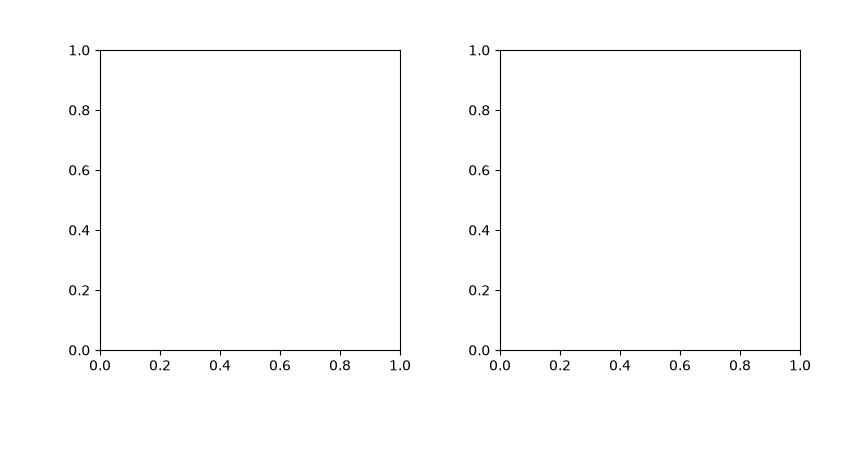

In [33]:
import project.visual.matplotlib as mpl_viz

def plot_metrics(df, output_path=None):
    specs = [
        ("E_cell.nrmse", "Elasticity NRMSE ↓", "tab:blue"),
        ("E_cell.pcorr", "Elasticity Pearson R ↑", "tab:orange"),
    ]

    fig, axes = mpl_viz.subplot_grid(
        1, 2, ax_height=3, ax_width=3, padding=(1.0,0.5,1.0,0.5), spacing=1.0
    )

    for ax, (key, label, color) in zip(axes.flat, specs):

        values = df[key].to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        
        if values.size == 0:
            raise ValueError(f"No finite values for {key}")

        q25, median, q75 = np.percentile(values, [25, 50, 75])

        ax.hist(
            values, bins=30, color=color,
            alpha=0.75, edgecolor="white",
        )
        ax.axvspan(q25, q75, color=color, alpha=0.15)
        ax.axvline(median, color="black", linestyle="--", linewidth=1.5)

        ax.text(
            0.8 if 'corr' in key else 0.97, 0.97,
            f"n = {values.size}\n"
            f"Median = {median:.3f}\n"
            f"IQR = [{q25:.3f}, {q75:.3f}]",
            transform=ax.transAxes,
            ha="right", va="top",
            fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9),
        )

        ax.set_xlabel(label)
        ax.set_ylabel("Number of cases")
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle("Linear-elastic inverse optimization")

    if output_path is not None:
        fig.savefig(output_path, dpi=300, bbox_inches="tight")

    return fig, axes

fig, axes = plot_metrics(df)

# Evaluation

In [44]:
complete_jobs = jobs.loc[
    jobs['output_type'].eq('Done')
]

lookup = complete_jobs.set_index(
    ['params.subject', 'params.mat_tag', 'params.material_type', 'params.curr_phase'], verify_integrity=True
)
lookup

job_name  \
params.subject params.mat_tag params.material_type params.curr_phase                         
4DCT_1_1       const          LE                   40                 job_e5e0d9c899deb90b   
                              NH                   40                 job_bbb80c50414a57ed   
               image          LE                   40                 job_40b3b6425c87e2a1   
                              NH                   40                 job_c62b17b249c31ed0   
               const          LE                   30                 job_9c90f37d71a23145   
...                                                                                    ...   
unknown_12_1   image          LE                   70                 job_e3da56f178f6c036   
               const          LE                   60                 job_d1f241796a7ee28e   
                              NH                   60                 job_5b841691a5aa0f59   
               image          LE                   60                 job_066a8e40d07e1e16   
                              NH                   60                 job_38536fcbf7a527e1   

                                                                      job_state  \
params.subject params.mat_tag params.material_type params.curr_phase              
4DCT_1_1       const          LE                   40                 COMPLETED   
                              NH                   40                 COMPLETED   
               image          LE                   40                 COMPLETED   
                              NH                   40                 COMPLETED   
               const          LE                   30                 COMPLETED   
...                                                                         ...   
unknown_12_1   image          LE                   70                 COMPLETED   
               const          LE                   60                 COMPLETED   
                              NH                   60                 COMPLETED   
               image          LE                   60                 COMPLETED   
                              NH                   60                 COMPLETED   

                                                                      n_submits  \
params.subject params.mat_tag params.material_type params.curr_phase              
4DCT_1_1       const          LE                   40                         1   
                              NH                   40                         1   
               image          LE                   40                         1   
                              NH                   40                         1   
               const          LE                   30                         1   
...                                                                         ...   
unknown_12_1   image          LE                   70                         1   
               const          LE                   60                         1   
                              NH                   60                         1   
               image          LE                   60                         1   
                              NH                   60                         1   

                                                                       job_id  \
params.subject params.mat_tag params.material_type params.curr_phase            
4DCT_1_1       const          LE                   40                 8529437   
                              NH                   40                 8529438   
               image          LE                   40                 8529439   
                              NH                   40                 8529440   
               const          LE                   30                 8529441   
...                                                                       ...   
unknown_12_1   image          LE                   

In [51]:
df.columns

Index(['group', 'label', 'num_voxels', 'E_vox.mean', 'E_vox.std', 'E_vox.rms',
       'num_cells', 'E_cell.mean', 'E_cell.std', 'E_cell.rms', 'u_cell.mean',
       'u_cell.std', 'u_cell.rms', 'u_cell.mae', 'u_cell.mre', 'u_cell.rmse',
       'u_cell.nrmse', 'res_cell.mean', 'res_cell.std', 'res_cell.rms',
       'source_path', 'job_name', 'job_id', 'params.config', 'params.variant',
       'params.subject', 'params.curr_phase', 'params.reg_tag',
       'params.mat_tag', 'params.material_type', 'params.tv_reg_weight',
       'params.random_seed'],
      dtype='object')

In [57]:
case_id = '4DCT_1_1'

df[df['params.subject'] == case_id] \
    .set_index(['params.subject', 'params.curr_phase', 'params.mat_tag', 'params.material_type']) \
    [['u_cell.nrmse', 'res_cell.rms', 'E_cell.rms']]

u_cell.nrmse  \
params.subject params.curr_phase params.mat_tag params.material_type                 
4DCT_1_1       40                const          LE                        0.118631   
                                                NH                        0.119427   
                                 image          LE                        0.120589   
                                                NH                        0.119917   
               30                const          LE                        0.059473   
                                                NH                        0.060007   
                                 image          LE                        0.058422   
                                                NH                        0.059390   
               20                const          LE                        0.035568   
                                                NH                        0.035497   
                                 image          LE                        0.035426   
                                                NH                        0.035315   
               10                const          LE                        0.026180   
                                                NH                        0.027556   
                                 image          LE                        0.026448   
                                                NH                        0.027586   
               0                 const          LE                        0.018656   
                                                NH                        0.019322   
                                 image          LE                        0.019045   
                                                NH                        0.019886   
               90                const          LE                        0.020362   
                                                NH                        0.021024   
                                 image          LE                        0.020590   
                                                NH                        0.021358   
               80                const          LE                        0.032674   
                                                NH                        0.033080   
                                 image          LE                        0.033284   
                                                NH                        0.034203   
               70                const          LE                        0.114712   
                                                NH                        0.116958   
                                 image          LE                        0.117940   
                                                NH                        0.117116   
               60                const          LE                        0.208882   
                                                NH                        0.211132   
                                 image          LE                        0.215947   
                                                NH                        0.211650   

                                                                      res_cell.rms  \
params.subject params.curr_phase params.mat_tag params.material_type                 
4DCT_1_1       40                const          LE                        0.002048   
                                                NH                        0.002042   
                                 image          LE                        0.002009   
                                                NH                        0.001988   
               30                const          LE                        0.003738   
                                                NH                        0.003696   
                                 image          LE                        0.003788   
                           

In [60]:
data_config = project.fileio.load_config('2026-11-01_config.yaml')['dataset']

data_config['variant']  = '2026-11-01'
data_config['subjects'] = [case_id]
data_config['state_pairs'] = [(50, 0)]

data_config['pipeline_tags']['image_registration']  = 'gil'
data_config['pipeline_tags']['material_properties'] = 'const'

ex = project.get_examples(data_config)[0]

Loading 2026-11-01_config.yaml
Gathering examples...
1 total


In [62]:
from collections import defaultdict
from pathlib import Path
import numpy as np

# load input image
nifti = project.fileio.load_nibabel(ex.paths['input_image'])
image = nifti.get_fdata()
affine = nifti.affine

vox_spacing = tuple(float(v) for v in affine[:3,:3] @ np.ones(3))

# load segmentation masks
domain = project.fileio.load_nibabel(ex.paths['domain_mask']).get_fdata() > 0

masks = {}
for p in ex.paths['init_state']['segment_dir'].iterdir():
    if str(p).endswith('.nii.gz'):
        masks[p.stem] = project.fileio.load_nibabel(p).get_fdata() > 0

# load true density and predicted elasticity maps

mat_tags = ['const', 'image']
mat_types = ['LE', 'NH']
phases = [0, 10, 20, 30, 40, 60, 70, 80, 90]

rho_trues = {}
E_preds = {}

for mat_tag in mat_tags:
    job = lookup.loc[case_id, mat_tag, 'LE', 0]
    rho_path = str(ex.paths['material_dir'] / 'density.nii.gz').replace('const', mat_tag)
    rho_trues[mat_tag] = project.fileio.load_nibabel(rho_path).get_fdata() * domain
    for mat_type in mat_types:
        for curr_phase in phases:
            job = lookup.loc[case_id, mat_tag, mat_type, curr_phase]
        
            E_path = Path(job.work_dir) / 'outputs' / 'optimize' / 'default' / case_id / 'rasters' / 'E_pred.nii.gz'
            E_preds[mat_tag, mat_type, curr_phase] = project.fileio.load_nibabel(E_path).get_fdata() * domain


Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/images/4DCT_1_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d_domain.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d/gt-500.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d/pleural_effusion.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d/gt-200.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d/lung_lower_lobe_left.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d/honeycombing.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC

In [66]:
def parse_loaded_mesh(stdout_path):
    with open(stdout_path) as f:
        lines = f.readlines()
    for line in lines:
        if line.startswith('Loading') and line.endswith('.xdmf\n'):
            return line[7:].strip()

mesh_pairs = (
    complete_jobs.assign(mesh_path=complete_jobs['stdout_path'].map(parse_loaded_mesh))
    .pivot(
        index=['params.subject', 'params.curr_phase', 'params.material_type'],
        columns='params.mat_tag',
        values='mesh_path',
    )
)
mesh_pairs

params.mat_tag                                                                                     const  \
params.subject params.curr_phase params.material_type                                                      
4DCT_10_1      0                 LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
               10                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
               20                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
                                 NH                    /restricted/projectnb/batmanlab/mragoza/data/B...   
               30                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
...                                                                                                  ...   
unknown_12_1   60                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
                                 NH                    /restricted/projectnb/batmanlab/mragoza/data/B...   
               70                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
               80                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   
               90                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...   

params.mat_tag                                                                                     image  
params.subject params.curr_phase params.material_type                                                     
4DCT_10_1      0                 LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
               10                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
               20                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
                                 NH                    /restricted/projectnb/batmanlab/mragoza/data/B...  
               30                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
...                                                                                                  ...  
unknown_12_1   60                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
                                 NH                    /restricted/projectnb/batmanlab/mragoza/data/B...  
               70                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
               80                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  
               90                LE                    /restricted/projectnb/batmanlab/mragoza/data/B...  

[161 rows x 2 columns]

In [67]:
import meshio

for key, pair in mesh_pairs.iterrows():
    print(f'\n{key}')

    for mat_tag in ['const', 'image']:
        path = pair[mat_tag]
        if not isinstance(path, str):
            print(f'  {mat_tag}: missing mesh path')
            continue

        mesh = meshio.read(path)
        rho = (
            np.asarray(mesh.point_data['rho']).ravel()
            if 'rho' in mesh.point_data
            else np.concatenate(mesh.cell_data['rho']).ravel()
        )

        print(
            f'  {mat_tag}: min={rho.min():.6g}, '
            f'mean={rho.mean():.6g}, max={rho.max():.6g}, '
            f'std={rho.std():.6g}'
        )



('4DCT_10_1', 0, 'LE')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 10, 'LE')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 20, 'LE')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 20, 'NH')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 30, 'LE')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 30, 'NH')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 40, 'LE')
  const: min=350, mean=350, max=350, std=5.56875e-15
  image: min=148.963, mean=538.484, max=1032.89, std=296.553

('4DCT_10_1', 40, 'NH')
  c

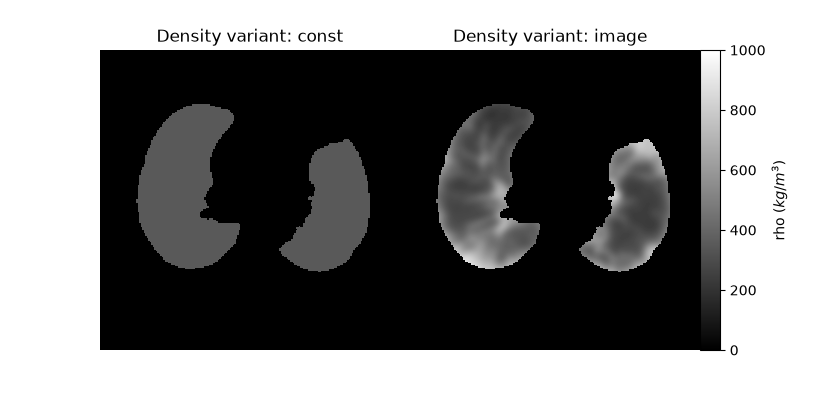

In [81]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

# Same slice and color scale for every phase.
z = 200
c = 100

fig, axes, cax = mpl_viz.subplot_grid(
    1, 
    len(mat_tags),
    ax_height=3,
    ax_width=3,
    padding=[1.0, 1.0, 0.5, 0.5],
    spacing=0.0,
    cbar_width=0.2
)

for col, mat_tag in enumerate(mat_tags):
    ax = axes[0,col]
    im = ax.imshow((rho_trues[mat_tag])[c:-c,c:-c,z].T, origin='lower', cmap='gray', vmin=0, vmax=1000)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'Density variant: {mat_tag}')
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.colorbar(im, cax=cax, label='rho ($kg/m^3$)')
plt.pause(1.0)

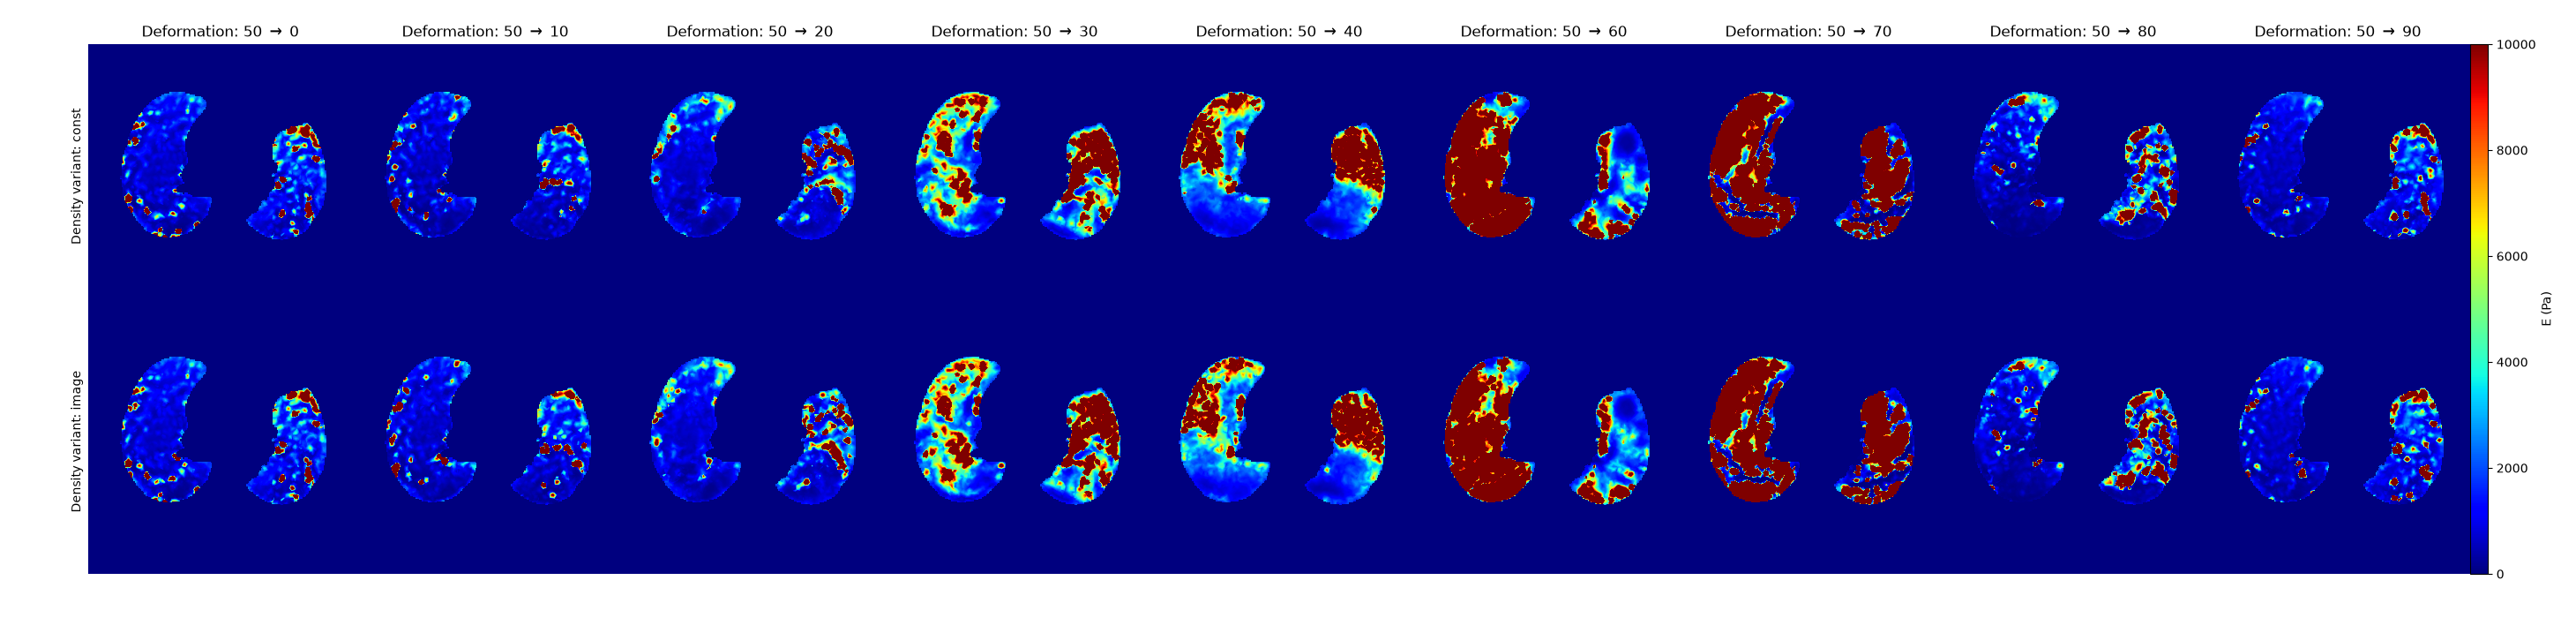

In [82]:
E_kws = dict(cmap='jet', vmin=0, vmax=1e4)

fig, axes, cax = mpl_viz.subplot_grid(
    len(mat_tags), 
    len(phases),
    ax_height=3,
    ax_width=3,
    padding=[1.0, 1.0, 0.5, 0.5],
    spacing=0.0,
    cbar_width=0.2
)

for row, mat_tag in enumerate(mat_tags):
    for col, phase in enumerate(phases):
        ax = axes[row,col]
        im = ax.imshow(E_preds[mat_tag,'LE',phase][c:-c,c:-c,z].T, origin='lower', **E_kws)
        if row == 0:
            ax.set_title(f'Deformation: 50 $\\to$ {phase}')
        if col == 0:
            ax.set_ylabel(f'Density variant: {mat_tag}')

        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

fig.colorbar(im, cax=cax, label='E (Pa)')
plt.pause(1.0)

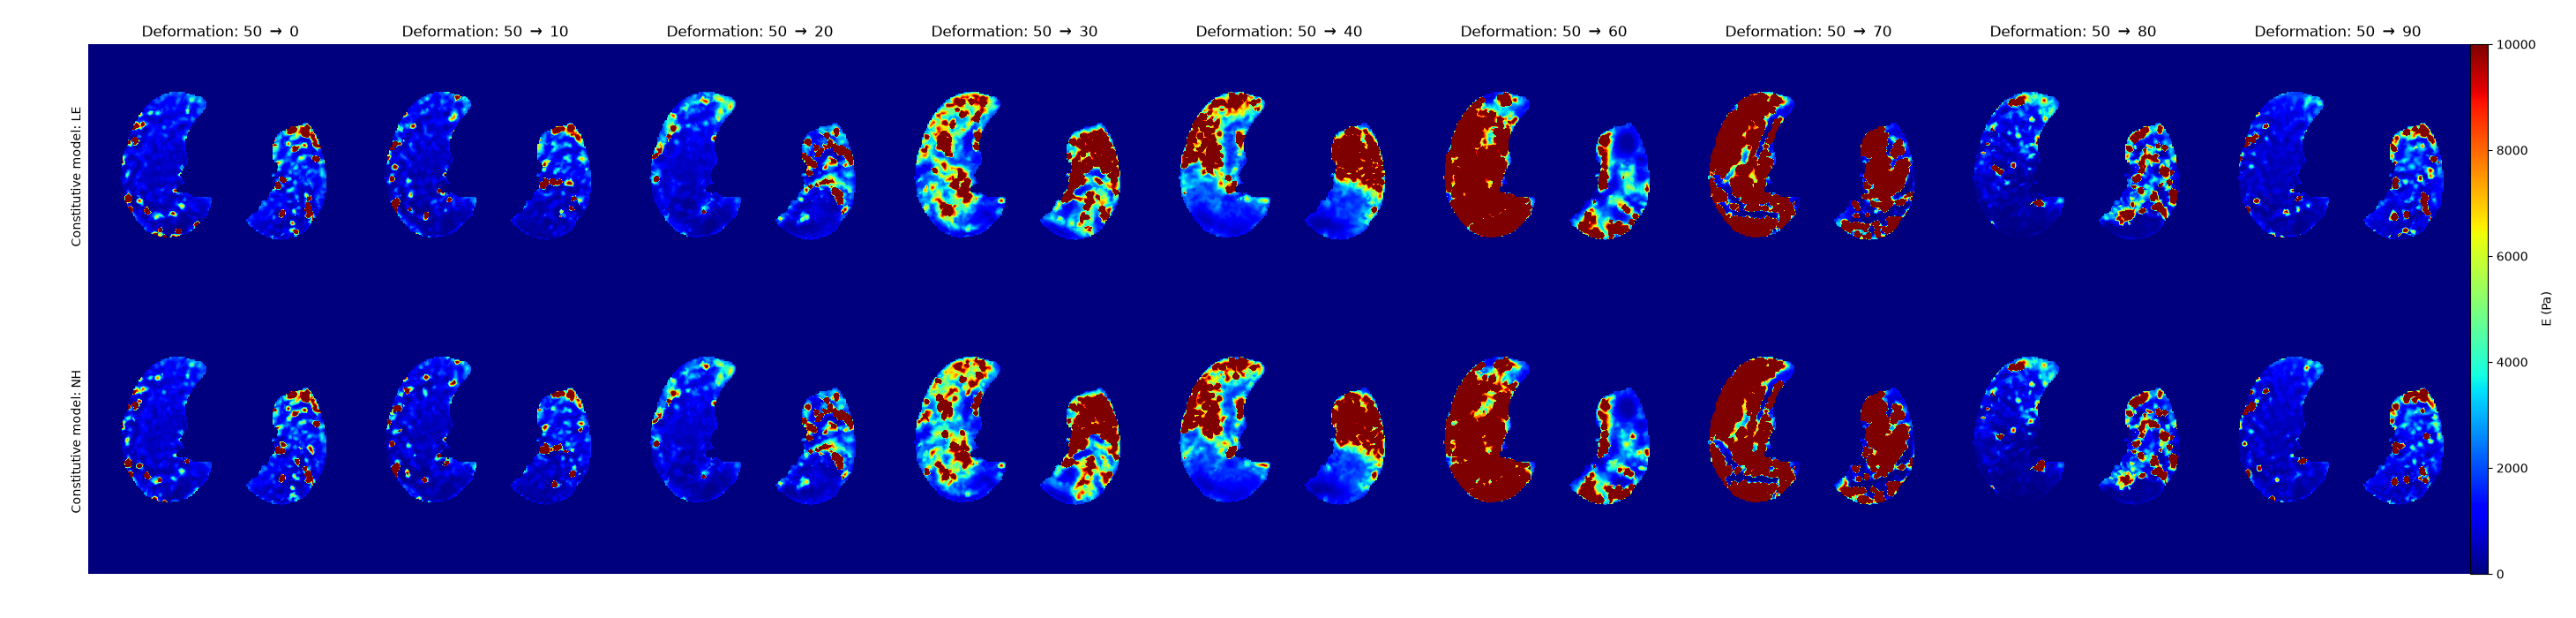

In [85]:
E_kws = dict(cmap='jet', vmin=0, vmax=1e4)

fig, axes, cax = mpl_viz.subplot_grid(
    len(mat_tags), 
    len(phases),
    ax_height=3,
    ax_width=3,
    padding=[1.0, 1.0, 0.5, 0.5],
    spacing=0.0,
    cbar_width=0.2
)

for row, mat_type in enumerate(mat_types):
    for col, phase in enumerate(phases):
        ax = axes[row,col]
        im = ax.imshow(E_preds['const',mat_type,phase][c:-c,c:-c,z].T, origin='lower', **E_kws)
        if row == 0:
            ax.set_title(f'Deformation: 50 $\\to$ {phase}')
        if col == 0:
            ax.set_ylabel(f'Constitutive model: {mat_type}')

        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

fig.colorbar(im, cax=cax, label='E (Pa)')
plt.pause(1.0)

In [188]:
import project.evaluation.metrics as eval_metrics

rows = []
for phase in phases:
    print(phase)
    a = E_preds[phase].reshape(-1, 1)
    b = E_preds[phase].reshape(-1, 1)
    m = domain.reshape(-1)
    a_median = np.median(a[m])
    b_median = np.median(b[m])
    rows.append({
        'phase': phase,
        'median_const': a_median,
        'median_image': b_median,
        'median_ratio': b_median / a_median,
        'nrmse': eval_metrics.normalized_rmse(a, b, m),
        'pcorr': eval_metrics.pearson_corr(a, b, m)
    })

density_eval = pd.DataFrame(rows).set_index('phase')
density_eval

0
10
20
30
40
60
70
80
90


,median_const,median_image,median_ratio,nrmse,pcorr
phase,,,,,
0,1101.270996,1163.588806,1.056587,0.228776,0.970029
10,789.908295,858.240326,1.086506,0.487049,0.869083
20,1323.225586,1383.740967,1.045733,0.458320,0.878430
30,2018.775330,2102.474854,1.041461,0.226263,0.968744
40,3329.555176,3428.434326,1.029697,0.494372,0.834121
60,2819.857788,2865.965698,1.016351,0.481420,0.856744
70,994.246338,1091.868652,1.098187,0.309388,0.939143
80,833.797974,911.677673,1.093404,0.462807,0.870851
90,1084.124939,1148.425049,1.059311,0.519730,0.844135


In [187]:
density_eval = pd.DataFrame(rows).set_index('phase')
density_eval

,nrmse,pcorr
phase,,
0,0.228776,0.970029
10,0.487049,0.869083
20,0.458320,0.878430
30,0.226263,0.968744
40,0.494372,0.834121
60,0.481420,0.856744
70,0.309388,0.939143
80,0.462807,0.870851
90,0.519730,0.844135


In [197]:
from itertools import combinations

def symmetric_normalized_rmse(a: np.ndarray, b: np.ndarray, weight=None) -> float:
    from project.evaluation.metrics import _rms, _divide
    num = _rms(np.linalg.norm(a - b, axis=1), weight)
    den = _rms(np.linalg.norm((a + b) / 2, axis=1), weight)
    return _divide(num, den)

rows = []
for p, q in combinations(phases, 2):
    print(p, q)
    a = E_const[p].reshape(-1, 1)
    b = E_const[q].reshape(-1, 1)
    m = domain.reshape(-1)
    rows.append({
        'phase_a': p,
        'phase_b': q,
        'nrmse': symmetric_normalized_rmse(a, b, m),
        'pcorr': eval_metrics.pearson_corr(a, b, m),
        'scorr': eval_metrics.spearman_corr(a, b, m)
    })

phase_eval = pd.DataFrame(rows)
phase_eval

0 10
0 20
0 30
0 40
0 60
0 70
0 80
0 90
10 20
10 30
10 40
10 60
10 70
10 80
10 90
20 30
20 40
20 60
20 70
20 80
20 90
30 40
30 60
30 70
30 80
30 90
40 60
40 70
40 80
40 90
60 70
60 80
60 90
70 80
70 90
80 90


,phase_a,phase_b,nrmse,pcorr,scorr
0,0,10,1.213284,0.409987,0.901689
1,0,20,1.370399,0.269179,0.838251
2,0,30,1.471040,0.183695,0.817468
3,0,40,1.698930,-0.008048,0.767092
4,0,60,1.797185,-0.055794,0.697439
5,0,70,1.747894,0.031992,0.757107
6,0,80,1.321536,0.327309,0.856361
7,0,90,0.691281,0.757464,0.946638
8,10,20,1.220084,0.392569,0.871000
9,10,30,1.495911,0.174391,0.844567


In [198]:
phase_eval.describe()

,phase_a,phase_b,nrmse,pcorr,scorr
count,36.000000,36.000000,36.000000,36.000000,36.000000
mean,25.000000,63.888889,1.495314,0.163758,0.796092
std,22.990681,23.937750,0.251530,0.193155,0.067686
min,0.000000,10.000000,0.691281,-0.057601,0.672856
25%,10.000000,40.000000,1.347444,-0.003082,0.755456
50%,20.000000,70.000000,1.529588,0.126753,0.795944
75%,40.000000,80.000000,1.697524,0.291650,0.844637
max,80.000000,90.000000,1.797185,0.757464,0.946638


In [205]:
rows = []
for phase, E in E_const.items():
    for region, mask in segments.items():
        print(phase, region)
        values = E[domain & mask]
        if values.size == 0:
            continue
        rows.append({
            'phase': phase,
            'region': region,
            'n_voxels': values.size,
            'E_mean': values.mean(),
            'E_median': np.median(values),
            'E_Q1': np.percentile(values, 25),
            'E_Q2': np.percentile(values, 75),
            'p_hi': np.mean(values >= 1e4),
            'p_lo': np.mean(values <= 1e2)
                
        })

region_df = pd.DataFrame(rows)

0 gt-500.nii
0 pleural_effusion.nii
0 gt-200.nii
0 lung_lower_lobe_left.nii
0 honeycombing.nii
0 nodule.nii
0 lt-850.nii
0 lung_airways_wall.nii
0 lung_upper_lobe_left.nii
0 lung_middle_lobe_right.nii
0 lt-950.nii
0 lung_veins.nii
0 consolidation.nii
0 ggo.nii
0 lung_airways.nii
0 lt-910.nii
0 emphysema.nii
0 lung_lower_lobe_right.nii
0 lung_arteries.nii
0 lung_upper_lobe_right.nii
10 gt-500.nii
10 pleural_effusion.nii
10 gt-200.nii
10 lung_lower_lobe_left.nii
10 honeycombing.nii
10 nodule.nii
10 lt-850.nii
10 lung_airways_wall.nii
10 lung_upper_lobe_left.nii
10 lung_middle_lobe_right.nii
10 lt-950.nii
10 lung_veins.nii
10 consolidation.nii
10 ggo.nii
10 lung_airways.nii
10 lt-910.nii
10 emphysema.nii
10 lung_lower_lobe_right.nii
10 lung_arteries.nii
10 lung_upper_lobe_right.nii
20 gt-500.nii
20 pleural_effusion.nii
20 gt-200.nii
20 lung_lower_lobe_left.nii
20 honeycombing.nii
20 nodule.nii
20 lt-850.nii
20 lung_airways_wall.nii
20 lung_upper_lobe_left.nii
20 lung_middle_lobe_right.nii

In [206]:
region_df[region_df.phase == 0]

,phase,region,n_voxels,E_mean,E_median,E_Q1,E_Q2,p_hi,p_lo
0,0,gt-500.nii,607184,6612.260359,1460.985352,719.845169,3979.587891,0.140994,0.003523
1,0,pleural_effusion.nii,1003,34482.758265,20282.490234,2928.570435,63658.746094,0.563310,0.000000
2,0,gt-200.nii,193235,8694.684265,1746.577881,778.539032,6118.938232,0.192636,0.003881
3,0,lung_lower_lobe_left.nii,467651,3589.442440,1220.201904,739.403809,2472.225830,0.070337,0.000975
4,0,honeycombing.nii,2491,26256.667795,18937.917969,8179.775635,36398.451172,0.699719,0.000000
5,0,nodule.nii,4,1237.294159,1260.682373,1086.998932,1410.977600,0.000000,0.000000
6,0,lt-850.nii,22013,2130.828450,1216.778809,900.679871,1757.208374,0.020215,0.001590
7,0,lung_airways_wall.nii,28697,5011.970708,1055.844360,617.371155,2641.293457,0.100324,0.003624
8,0,lung_upper_lobe_left.nii,508162,3281.162232,1428.121338,897.438599,2574.500671,0.059802,0.000498
9,0,lung_middle_lobe_right.nii,241911,1309.530300,765.932251,519.626251,1221.362427,0.010475,0.000360


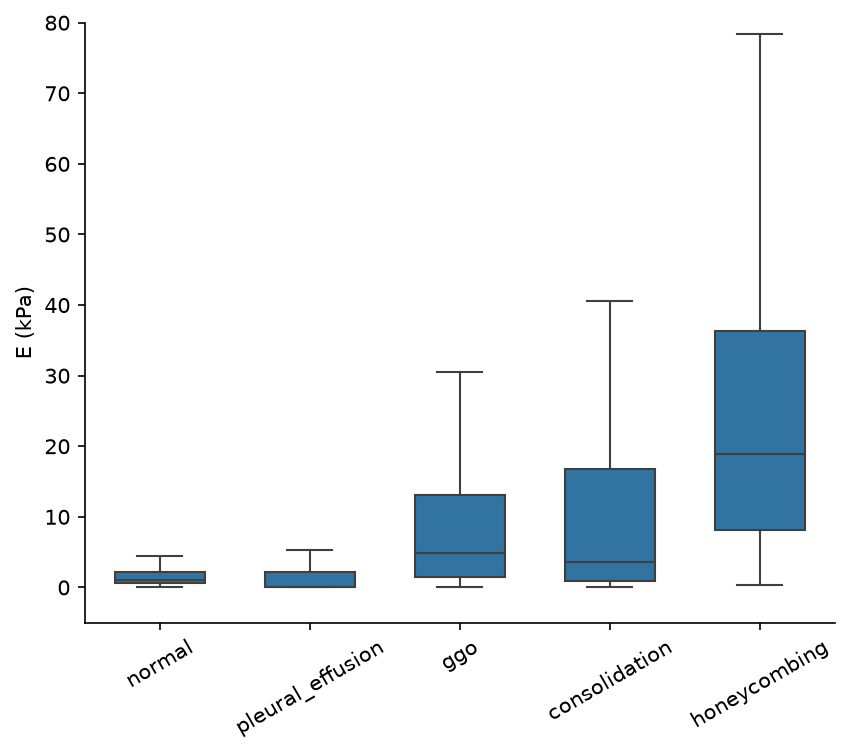

In [269]:
def plot_distributions(E, masks, regions, kind="box", output_path=None, relative=False):
    import seaborn as sns

    regions = [
        r for r in regions if np.count_nonzero(masks[r]) >= 100
    ]

    if relative:
        unit = np.median(E[masks['normal']])
    else:
        unit = 1000.

    data = pd.concat([
        pd.DataFrame({
            "region": r,
            "E": E[np.asarray(masks[r], dtype=bool)].ravel() / unit,
        }) for r in regions
    ], ignore_index=True)

    data = data.loc[np.isfinite(data["E"])]

    fig, axes = mpl_viz.subplot_grid(
        1, 1,
        ax_height=4, 
        ax_width=max(4, len(regions)),
        padding=(1.0, 0.5, 1.0, 0.5),
        spacing=1.0
    )
    ax = np.asarray(axes).ravel()[0]

    kwargs = dict(data=data, x="region", y="E", order=regions, ax=ax)

    if kind == "violin":
        sns.violinplot(**kwargs, inner="quartile", cut=0)
    else:
        sns.boxplot(**kwargs, showfliers=False, width=0.6)

    if relative:
        ax.set(xlabel="", ylabel="E (relative)")
    else:
        ax.set(xlabel="", ylabel="E (kPa)")

    ax.tick_params(axis="x", labelrotation=30)
    ax.spines[["top", "right"]].set_visible(False)

    if relative:
        ax.set_ylim(0, 100)
    else:
        ax.set_ylim(-5, 80)

    if output_path is not None:
        fig.savefig(output_path, dpi=300, bbox_inches="tight")

    return fig, axes

for k, v in segments.items():
    segments[k] = (v > 0)

segments['parenchyma'] = (
    segments['lung_upper_lobe_left'] |
    segments['lung_lower_lobe_left'] | 
    segments['lung_upper_lobe_right'] | 
    segments['lung_middle_lobe_right'] | 
    segments['lung_lower_lobe_right']
) & ~(
    segments['lung_airways'] | segments['lung_arteries'] | segments['lung_veins']
)
segments['emphysema'] = segments['parenchyma'] & segments['lt-950']
segments['disease'] = segments['parenchyma'] & (
    segments['pleural_effusion'] |
    segments['honeycombing'] |
    segments['nodule'] | 
    segments['consolidation'] | 
    segments['ggo'] | 
    segments['emphysema']
)
segments['normal'] = segments['parenchyma'] & ~segments['disease']

fig, axes = plot_distributions(
    E_const[0],
    segments,
    regions=["normal", "pleural_effusion", "emphysema", "ggo", "consolidation", "nodule", "honeycombing"],
    kind="box",
    relative=False
)
fig

In [63]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

img_kws = dict(cmap='gray', vmin=-1000, vmax=-500)
rho_kws = dict(cmap='gray', vmin=0, vmax=1000)
E_p_kws = dict(cmap='jet', vmin=0, vmax=1e4)
err_kws = dict(cmap='seismic', vmin=-1, vmax=1)

grid_kws = dict(cbar_width=0.2, padding=(0.5, 0.65, 0.35, 0.3))

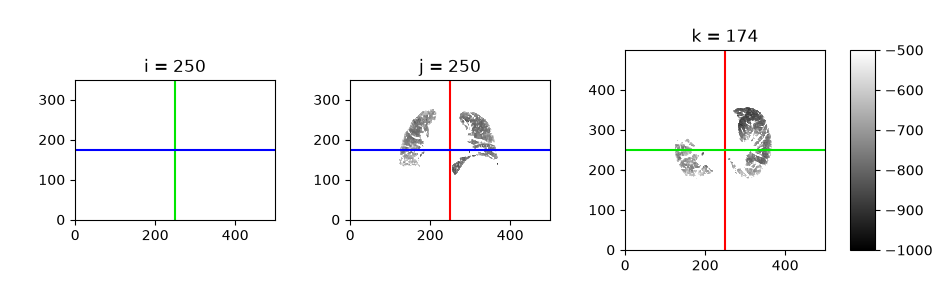

In [67]:
mpl_viz.SliceViewer(image * mask, vox_spacing=vox_spacing, **img_kws)
plt.pause(1.0)

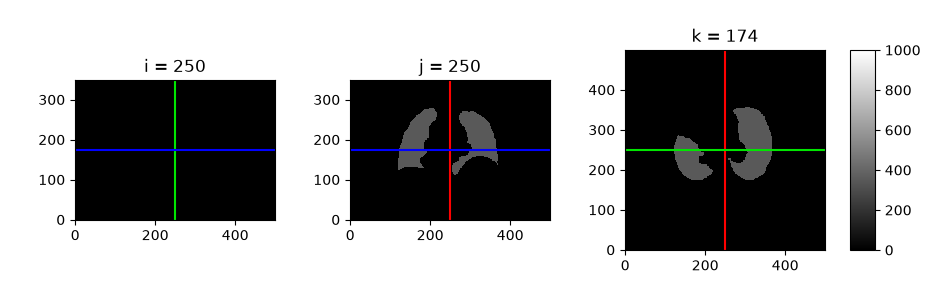

In [68]:
mpl_viz.SliceViewer(rho_true * mask, vox_spacing=vox_spacing, **rho_kws)
plt.pause(1.0)

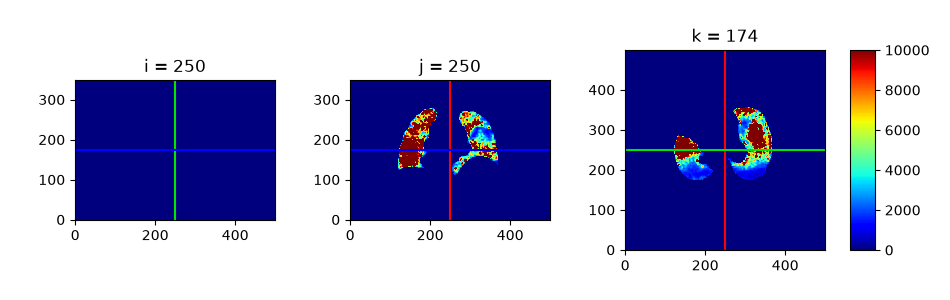

In [73]:
mpl_viz.SliceViewer(E_pred * mask, vox_spacing=vox_spacing, **E_p_kws)
plt.pause(1.0)